In [302]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

In [303]:
# File path
file_path = r"D:\MG\！CUHKSZ\Berkeley 交流\❗课\STAT 153 - Intro to Time Series\Homework\3_MRTSSM4453USN.xlsx"

# Load data
df = pd.read_excel(file_path, sheet_name='Monthly')
df['observation_date'] = pd.to_datetime(df['observation_date'])
df = df.sort_values('observation_date').reset_index(drop=True)
df['log_sales'] = np.log(df['MRTSSM4453USN'])
df['t'] = np.arange(len(df))

In [304]:
print(df.head())

  observation_date  MRTSSM4453USN  log_sales  t
0       1992-01-01           1414   7.254178  0
1       1992-02-01           1444   7.275172  1
2       1992-03-01           1496   7.310550  2
3       1992-04-01           1569   7.358194  3
4       1992-05-01           1707   7.442493  4


# b) Model Comparison

In [305]:
# Identify t0 (April 2020)
t0 = df[df['observation_date'] == '2020-04-01'].index[0]
df['indicator'] = (df.index >= t0).astype(int)
df['t_indicator'] = df['t'] * df['indicator']

In [306]:
# Fit models
X6 = sm.add_constant(df['t'])
model6 = sm.OLS(df['log_sales'], X6).fit()

In [307]:
X7 = sm.add_constant(df[['t', 'indicator', 't_indicator']])
model7 = sm.OLS(df['log_sales'], X7).fit()

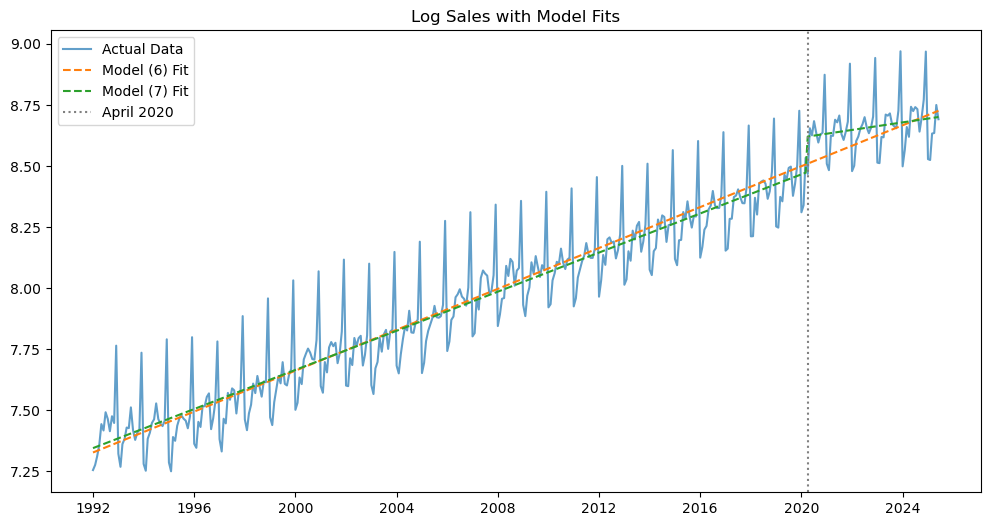

In [308]:
# Plot
plt.figure(figsize=(12, 6))
plt.plot(df['observation_date'], df['log_sales'], label='Actual Data', alpha=0.7)
plt.plot(df['observation_date'], model6.predict(X6), label='Model (6) Fit', linestyle='--')
plt.plot(df['observation_date'], model7.predict(X7), label='Model (7) Fit', linestyle='--')
plt.axvline(pd.Timestamp('2020-04-01'), color='gray', linestyle=':', label='April 2020')
plt.legend()
plt.title('Log Sales with Model Fits')
plt.show()

# c) Posterior Probabilities

In [309]:
# Extract coefficients and covariance
beta = model7.params
cov = model7.cov_params()
names = ['const', 't', 'indicator', 't_indicator']

In [310]:
# P(β3 < 0)
from scipy.stats import norm
beta3_mean = beta['t_indicator']
beta3_std = np.sqrt(cov.loc['t_indicator', 't_indicator'])
p_beta3_neg = norm.cdf(0, beta3_mean, beta3_std)

In [311]:
# P(β2 + β3*t0 > 0)
linear_comb = beta['indicator'] + beta['t_indicator'] * t0
var_comb = (
    cov.loc['indicator', 'indicator'] +
    cov.loc['t_indicator', 't_indicator'] * t0**2 +
    2 * t0 * cov.loc['indicator', 't_indicator']
)
p_comb_pos = 1 - norm.cdf(0, linear_comb, np.sqrt(var_comb))

In [312]:
print(f"P(β3 < 0) = {p_beta3_neg}")
print(f"P(β2 + β3*t0 > 0) = {p_comb_pos}")

P(β3 < 0) = 0.9930025572261887
P(β2 + β3*t0 > 0) = 0.9999956169434654


# d) Fourier Model

In [313]:
# Fourier terms
for i in range(1, 5):
    df[f'cos_{i}'] = np.cos(2 * np.pi * i * df['t'] / 12)
    df[f'sin_{i}'] = np.sin(2 * np.pi * i * df['t'] / 12)

In [314]:
# Fit models for k=1 to k=4 and select based on AIC
best_aic = np.inf
best_k = None
best_model = None

for k in range(1, 5):
    fourier_cols = []
    for i in range(1, k+1):
        fourier_cols.append(f'cos_{i}')
        fourier_cols.append(f'sin_{i}')
    X = sm.add_constant(df[['t', 'indicator', 't_indicator'] + fourier_cols])
    model = sm.OLS(df['MRTSSM4453USN'], X).fit()
    if model.aic < best_aic:
        best_aic = model.aic
        best_k = k
        best_model = model

In [315]:
print(f"Best k: {best_k} (AIC = {best_aic})")

Best k: 4 (AIC = 5703.939737721996)


# e) Forecast with Model (8)

In [316]:
# Generate future time points for the next 36 months
n_forecast = 36
last_date = df['observation_date'].iloc[-1]
future_dates = pd.date_range(start=last_date + pd.DateOffset(months=1), periods=n_forecast, freq='MS')
last_t = df['t'].iloc[-1]
future_t = np.arange(last_t + 1, last_t + n_forecast + 1)

In [317]:
# Create a DataFrame for future data
future_df = pd.DataFrame({'observation_date': future_dates, 't': future_t})
future_df['indicator'] = 1  # Since all future t >= t0
future_df['t_indicator'] = future_df['t']  # Because indicator=1

In [318]:
# Add Fourier terms
for i in range(1, best_k + 1):
    future_df[f'cos_{i}'] = np.cos(2 * np.pi * i * future_df['t'] / 12)
    future_df[f'sin_{i}'] = np.sin(2 * np.pi * i * future_df['t'] / 12)

In [319]:
# Prepare the design matrix for prediction - manually create with correct column names
future_X = pd.DataFrame({'const': np.ones(len(future_df))})
future_X['const'] = 1  # Add constant term with correct name
future_X['t'] = future_df['t']
future_X['indicator'] = future_df['indicator']
future_X['t_indicator'] = future_df['t_indicator']

In [320]:
# Add Fourier terms
for i in range(1, best_k + 1):
    future_X[f'cos_{i}'] = future_df[f'cos_{i}']
    future_X[f'sin_{i}'] = future_df[f'sin_{i}']

In [321]:
# Ensure column order matches the model's expectations
future_X = future_X[best_model.model.exog_names]  # Reorder columns to match the model

In [322]:
# Predict sales for the future
future_pred = best_model.predict(future_X)

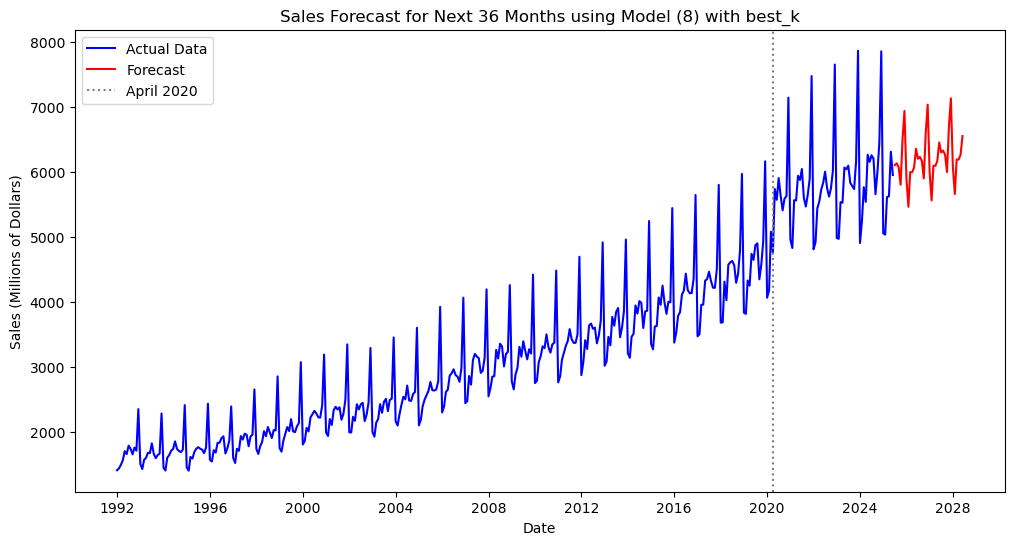

In [323]:
# Plot original data and forecast
plt.figure(figsize=(12, 6))
plt.plot(df['observation_date'], df['MRTSSM4453USN'], label='Actual Data', color='blue')
plt.plot(future_df['observation_date'], future_pred, label='Forecast', color='red')
plt.axvline(pd.Timestamp('2020-04-01'), color='gray', linestyle=':', label='April 2020')
plt.legend()
plt.title('Sales Forecast for Next 36 Months using Model (8) with best_k')
plt.xlabel('Date')
plt.ylabel('Sales (Millions of Dollars)')
plt.show()